In [114]:
import numpy as np
import scipy.io as sio
import matplotlib.pyplot as plt

raw = sio.loadmat("../data/Indian_pines_corrected.mat")

print(raw.keys())

dict_keys(['__header__', '__version__', '__globals__', 'indian_pines_corrected'])


In [115]:
X = raw["indian_pines_corrected"].astype(float)

#Cargamos el dataset de HSI para gt
gt = sio.loadmat("../data/Indian_pines_gt.mat")["indian_pines_gt"]

print("Imagen: ", X.shape, X.dtype, X.min(), X.max())
print("Mapa:     ", gt.shape, gt.dtype, np.unique(gt))

Imagen:  (145, 145, 200) float64 955.0 9604.0
Mapa:      (145, 145) uint8 [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16]


 0 Sin etiqueta               10776 píxeles
 1 Alfalfa                       46 píxeles
 2 Maíz sin labranza           1428 píxeles
 3 Maíz labranza mínima         830 píxeles
 4 Maíz                         237 píxeles
 5 Pasto-pastizal               483 píxeles
 6 Pasto-árboles                730 píxeles
 7 Pasto segado                  28 píxeles
 8 Heno en hileras              478 píxeles
 9 Avena                         20 píxeles
10 Soya sin labranza            972 píxeles
11 Soya labranza mínima        2455 píxeles
12 Soya limpia                  593 píxeles
13 Trigo                        205 píxeles
14 Bosque                      1265 píxeles
15 Edificios-pasto-árboles      386 píxeles
16 Torres de acero               93 píxeles


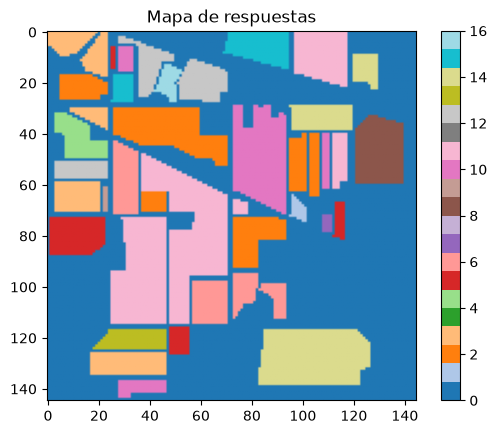

In [116]:
clases = ["Sin etiqueta", "Alfalfa", "Maíz sin labranza", "Maíz labranza mínima", "Maíz",
          "Pasto-pastizal", "Pasto-árboles", "Pasto segado", "Heno en hileras", "Avena",
          "Soya sin labranza", "Soya labranza mínima", "Soya limpia", "Trigo", "Bosque",
          "Edificios-pasto-árboles", "Torres de acero"]

valores, cuentas = np.unique(gt, return_counts=True)
for v, n in zip(valores, cuentas):
    print(f"{v:2d} {clases[v]:25s} {n:6d} píxeles")

plt.imshow(gt, cmap="tab20"); plt.colorbar(); plt.title("Mapa de respuestas")
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

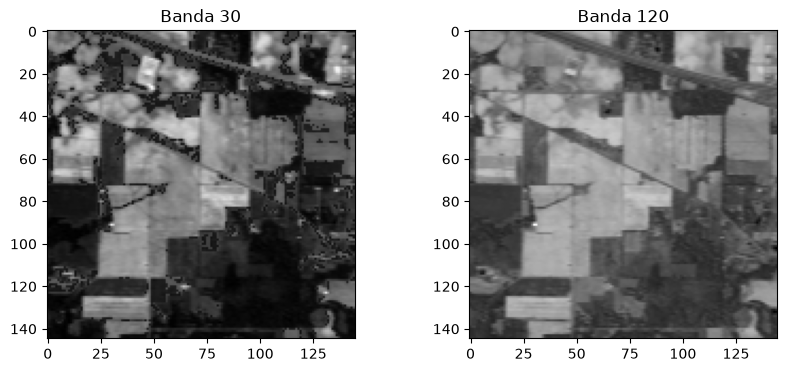

In [117]:
#Paso 3: Ver una banda

fig, ax = plt.subplots(1, 2, figsize=(10,4))
ax[0].imshow(X[:, :, 30], cmap="gray"); ax[0].set_title("Banda 30")
ax[1].imshow(X[:, :, 120], cmap="gray"); ax[1].set_title("Banda 120")
plt.show

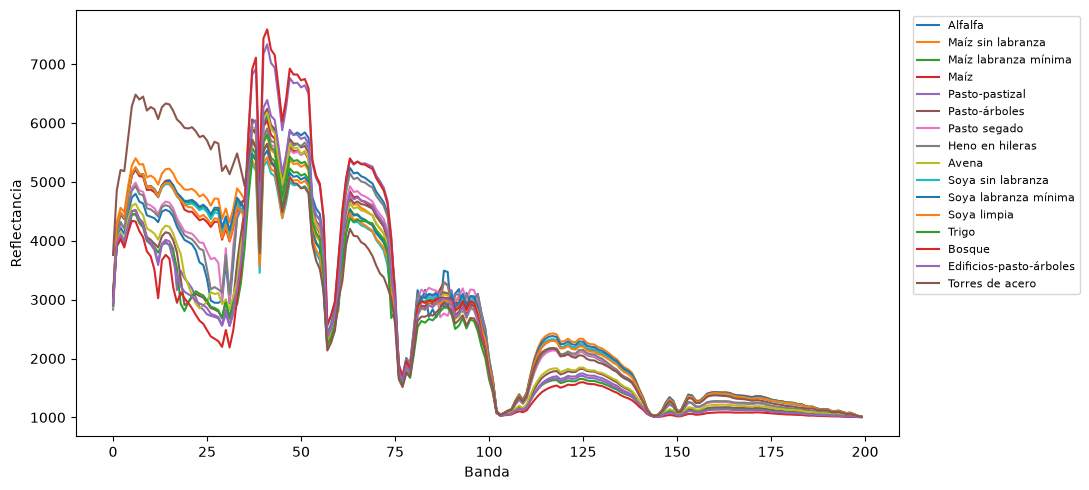

In [118]:
# Paso 4: Graficar la firma promedio de cada clase
plt.figure(figsize=(11, 5))
for c in range(1, 17):
    pixeles_c = X[gt == c]              # todos los píxeles de la clase c
    firma = pixeles_c.mean(axis=0)      # promedio de cada banda
    plt.plot(firma, label=clases[c])
plt.xlabel("Banda"); plt.ylabel("Reflectancia")
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

In [119]:
from numpy import linalg
# Paso 5: SAM entre dos firmas

def sam(a,b):
    cos = a @ b / (np.linalg.norm(a) * np.linalg.norm(b))
    return np.arccos(np.clip(cos, -1, 1))

maiz = X[gt==4].mean(axis=0)
soya = X[gt==1].mean(axis=0)
bosque = X[gt==14].mean(axis=0)

print("Maiz vs Soya: ", sam(maiz, soya))
print("Maíz vs bosque: ", sam(maiz, bosque))

Maiz vs Soya:  0.09803857675738098
Maíz vs bosque:  0.24405916692163176


In [120]:
#Paso 6. SAM vectorizado: todos los pixeles a la vez
ref = maiz

producto = X @ ref  

normas = np.linalg.norm(X, axis = 2)

cos = producto / (normas * np.linalg.norm(ref) + 1e-12)

mapa_sam = np.arccos(np.clip(cos, -1, 1))

print(mapa_sam.shape, mapa_sam.min(), mapa_sam.max())


(145, 145) 0.02422705454297495 0.31515320475202996


<function matplotlib.pyplot.show(close=None, block=None)>

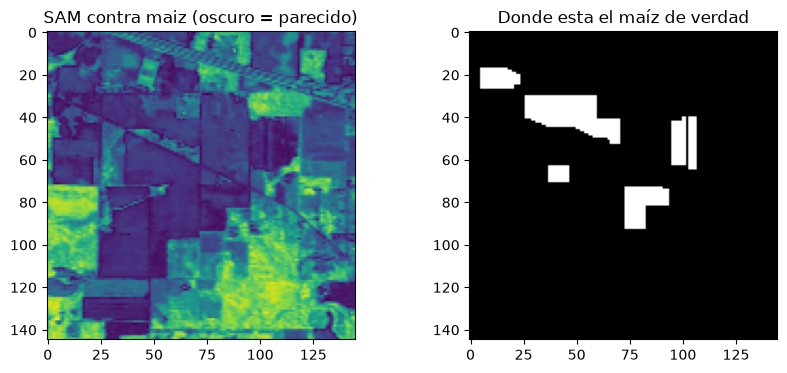

In [121]:
fig, ax = plt.subplots(1, 2, figsize=(10,4))
ax[0].imshow(mapa_sam, cmap="viridis"); ax[0].set_title("SAM contra maiz (oscuro = parecido)")
ax[1].imshow(gt == 2, cmap="gray"); ax[1].set_title("Donde esta el maíz de verdad")

plt.show

In [122]:
#Paso 8

x = maiz
y = 2 * x

print("SAM: ", sam(x,y))
print("Euclidiana:",np.linalg.norm(x - y))

SAM:  0.0
Euclidiana: 45492.02094420605


In [ ]:
# Observaciones

# La vectorización es esencial para el procesamiento de HSI
# El mapa de SAM con referencia del maiz muestra ciertas secciones de la misma intensidad que el maiz, pero que 
# en el mapa de etiqueas no aparecen marcados como maiz.